<a href="https://colab.research.google.com/github/Cpea8713/Lab1/blob/main/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS4487 Week 10 - Assignment

### Outline

Our Goals with this Project:

1. Import and review the data
2. Perform EDA and Clean Data
3. Fit a model
4. Test the accuracy of the model
6.  Use the model to predict on a new dataset (without the target)

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Business Context AdviseInvest
You work on a small team of data analysts at AdviseInvest, a venture-backed startup. The Director of Sales at AdviseInvest has approached your team asking for help solving a staffing problem.

### The Company
The company's mission is to provide tools and support to help ordinary people gain control of their personal finances. The company leverages technology to provide affordable financial advice to a national client base.

Customers who reach AdviseInvest's website go through five steps:

- Open an account.
- Complete a customer profile form with basic information about their background and finances.
- Schedule a free phone conversation with a sales representative during a 1-hour window of time.
- Attend the free phone conversation.
- Buy a financial plan.
- There are three types of financial plans: Beginner, Intermediate, and Advanced. Each is sold at a different price, and there are varying degrees of personalization. After a customer purchases a financial plan, the customer is assigned a financial planner who helps determine the customer's goals and advises the customer on spending decisions.

### The Problem
Some customers are lost at each stage of the process. Steps 3 and 4 are particularly challenging because approximately 50% of those who schedule a phone conversation fail to pick up the call. This leads to inefficiencies from a staffing perspective.

AdviseInvest has 4 sales reps on staff during each particular 1-hour window. Each of the 4 reps is assigned 2 prospective customers per hour, which means that the company schedules a total of 8 phone calls per hour. The calls are outgoing: sales reps call customers who scheduled a phone conversation during that hour window.

Unfortunately, as noted above, many of the customers who scheduled a call do not answer. As a consequence, sales reps are often left underutilized. Moreover, they are underutilized unevenly. For example, it is possible that one sales rep will not do any sales calls during that hour, whereas another will be busy the entire hour with two calls. Sales reps have nothing to do when customers do not answer the scheduled phone call.

### AdviseInvest Data Dictionary


| Variable | Description | Type | Code |
|:---|:---|:---|:---|
| customer_id | Unique customer identifier | Numeric | |
| Answered | Customer response | Binary | 0: customer did not answer scheduled call; 1: customer answered scheduled call |
| Income | Customer income in US dollars | Numeric | |
| Female | Customer gender | Binary | 0: male; 1: female |
| Age | Age in years | Numeric | |
| Job | Nature of job | Categorical | 0 : unemployed; 1 : entry level position; 2 : midlevel position; 3 : management/ self-employed/ highly qualified employee/ officer |
| Num_dependents | Number of people for whom the customer provides maintenance | Numeric | |
| Rent | Customer rents | Binary | 0: no; 1: yes |
| Own_res | Customer owns residence | Binary | 0: no; 1: yes |
| New_car | Recent new car purchase | Binary | New car purchase in the last 3 months: 0: no, 1: yes |
| Chk_acct | Checking account status | Categorical | 0 : no checking account; 1: checking < 200 USD; 2 : 200 < checking < 2000 USD; 3: 2000 < checking < 35000 USD; 4: >= 3500 USD |
| Sav_acct | Average balance in savings account | Categorical | 0 : no savings account; 1 : 100 <= savings < 500 USD; 2 : 500 <= savings < 2000 USD; 3 : 2000 < savings < 35000 USD; 4: >= 3500 USD |
| Num_accts | Number of accounts owned by customer | Numeric | |
| Mobile | Mobile phone | Binary | 0: customer provided non‐mobile phone for follow‐up call; 1: customer provided mobile phone for follow‐up call |
| Product | Type of product purchased after conversation with sales rep | Categorical | 0: customer did not answer call; 1: customer answered but did not purchase a product; 2: customer answered and purchased Beginner plan; 3: customer answered and purchased Intermediate plan; 4: customer answered and purchased Advanced plan |

### Load Libraries

Import the libraries you will need, such as:
- Pandas
- Sklearn
- Matplotlib


In [ ]:
# Add code here 🔧
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix

## Step 1: Initial Data Understanding

### Do the following:
 - Import data from the AdviseInvest historical dataset into a dataframe (in GitHub go to the DataSets folder and look for `adviseinvest_historical_data.csv`)
 - Describe or profile the dataframe
 - Look for any outliers, missing values, or duplicates

In [ ]:
df = pd.read_csv('adviseinvest_historical_data.csv')
display(df.head())
df.info()
display(df.describe())
display(df.isnull().sum())
display(df.duplicated().sum())

,customer_id,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
0,10098,0,-65600,0,24,2,1,0,1,1.0,1,1,3,0,0
1,184,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
2,194,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0
3,689,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
4,811,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29504 entries, 0 to 29503
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   customer_id     29504 non-null  int64  
 1   answered        29504 non-null  int64  
 2   income          29504 non-null  int64  
 3   female          29504 non-null  object 
 4   age             29504 non-null  int64  
 5   job             29504 non-null  int64  
 6   num_dependents  29504 non-null  int64  
 7   rent            29504 non-null  int64  
 8   own_res         29504 non-null  int64  
 9   new_car         29502 non-null  float64
 10  chk_acct        29504 non-null  int64  
 11  sav_acct        29504 non-null  int64  
 12  num_accts       29504 non-null  int64  
 13  mobile          29504 non-null  int64  
 14  product         29504 non-null  int64  
dtypes: float64(1), int64(13), object(1)
memory usage: 3.4+ MB


,customer_id,answered,income,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
count,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29502.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000
mean,14850.475563,0.546638,33766.893303,34.773454,1.915401,1.140998,0.210412,0.681128,0.240797,1.468547,0.956616,2.458345,0.091106,1.535792
std,8517.254310,0.497829,29379.202710,11.369865,0.658183,0.348025,0.407608,0.466047,0.427575,1.234727,1.483946,19.497380,0.287765,1.625916
min,99.000000,0.000000,-65600.000000,19.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,7474.750000,0.000000,13550.000000,26.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000
50%,14850.500000,1.000000,23310.000000,32.000000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,2.000000,0.000000,1.000000
75%,22226.250000,1.000000,41690.000000,40.000000,2.000000,1.000000,0.000000,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000,3.000000
max,29602.000000,1.000000,159450.000000,132.000000,3.000000,2.000000,1.000000,1.000000,1.000000,3.000000,4.000000,3345.000000,1.000000,4.000000


,0
customer_id,0
answered,0
income,0
female,0
age,0
job,0
num_dependents,0
rent,0
own_res,0
new_car,2


np.int64(3)

### Reflection:
1.1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1.1. The dataset has 29,504 rows and 15 columns. There are 2 missing values in new_car and no duplicates. I noticed some unusual values like negative income, age of 132, and a very high number of accounts. The female column is also stored as an object.

# Step 2: Data Preparation

## 2.1: Data Cleanup

### Do the following:
- 2.1 Check for and remove any outliers
- 2.2 Consider fixing any missing data (should you delete the record or impute the value?)
- 2.3 remove any variables, like customer_id, that are not helpful in predicting the target variable (hint: are there any variables that are available only AFTER the customer has answered, and wouldn't be useful in predicting?)
- 2.4 Clean up the data and put it in a new dataframe named "df_clean"


In [ ]:
display(df[df['income'] < 0])
display(df[df['age'] > 100])
display(df[df['num_accts'] > 100])

,customer_id,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
0,10098,0,-65600,0,24,2,1,0,1,1.0,1,1,3,0,0
13376,198,1,-15430,1,33,2,1,0,1,0.0,3,3,2,0,2


,customer_id,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
1153,132,0,9310,0,132,1,1,0,1,1.0,1,1,1,0,0


,customer_id,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
24415,15098,1,30590,1,61,1,1,0,1,0.0,3,3,3345,0,4


In [ ]:
df_clean = df.copy()
df_clean = df_clean[df_clean['income'] >= 0]
df_clean = df_clean[df_clean['age'] <= 100]
df_clean = df_clean[df_clean['num_accts'] <= 100]
df_clean = df_clean.dropna()
df_clean = df_clean.drop_duplicates()
df_clean = df_clean[df_clean['female'].isin(['0', '1'])].copy()
df_clean['female'] = df_clean['female'].astype(int)
df_clean = df_clean.drop(columns=['customer_id', 'product'])
print(df_clean.shape)
print(df_clean.dtypes)
print(df_clean.isnull().sum())

(29494, 13)
answered            int64
income              int64
female              int64
age                 int64
job                 int64
num_dependents      int64
rent                int64
own_res             int64
new_car           float64
chk_acct            int64
sav_acct            int64
num_accts           int64
mobile              int64
dtype: object
answered          0
income            0
female            0
age               0
job               0
num_dependents    0
rent              0
own_res           0
new_car           0
chk_acct          0
sav_acct          0
num_accts         0
mobile            0
dtype: int64


### Reflection:
2.5  Explain the steps that you took to clean outliers and missing data.  Why did you chose the approach that you used?

2.6  Which variables did you remove, and why?

### ✍️ Your Response: 🔧
2.5 I removed rows with unrealistic values like negative income, ages over 100, and more than 100 accounts. I also removed rows with missing values, duplicates, and an invalid value in the female column. I chose this approach because there were only a few problematic rows, so removing them wouldn't significantly affect the dataset.

2.6 I removed customer_id because it is just an identifier and doesn't help predict whether someone will answer. I also removed product because that information is only available after the customer answers the call.

## 2.2: Standardize variables

### Do the following:
 - Change "answered" to a boolean (true/false) type
 - Convert any variables that should be an integer into an integer

In [ ]:
df_clean['answered'] = df_clean['answered'].astype(bool)
df_clean['new_car'] = df_clean['new_car'].astype(int)
print(df_clean.dtypes)

answered           bool
income            int64
female            int64
age               int64
job               int64
num_dependents    int64
rent              int64
own_res           int64
new_car           int64
chk_acct          int64
sav_acct          int64
num_accts         int64
mobile            int64
dtype: object


## 2.3 Convert variables

### Do the following:
- convert at least 3 variables to categorical where that data type is appropriate

In [ ]:
df_clean['female'] = df_clean['female'].astype('category')
df_clean['job'] = df_clean['job'].astype('category')
df_clean['rent'] = df_clean['rent'].astype('category')
print(df_clean.dtypes)

answered              bool
income               int64
female            category
age                  int64
job               category
num_dependents       int64
rent              category
own_res              int64
new_car              int64
chk_acct             int64
sav_acct             int64
num_accts            int64
mobile               int64
dtype: object


# Step 3: Exploratory Data Analysis (EDA)

### Do the following:
- Explore the relationships between the target and independent variables
- Create at least five charts to show the relationships, using different chart types that are approriate to the analysis
- Ensure that all charts are clearly labeled and formatted



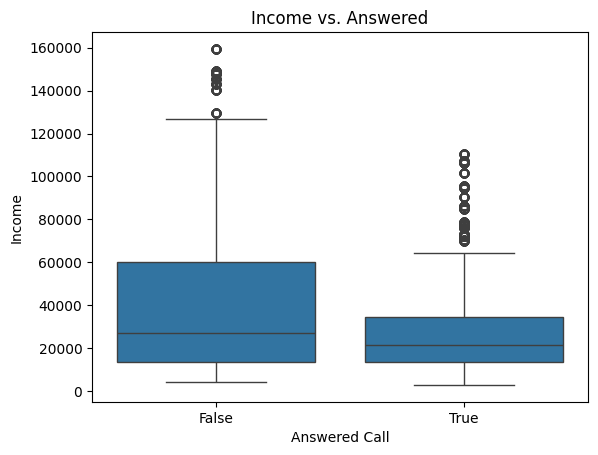

In [ ]:
sns.boxplot(data=df_clean, x='answered', y='income')
plt.title('Income vs. Answered')
plt.xlabel('Answered Call')
plt.ylabel('Income')
plt.show()

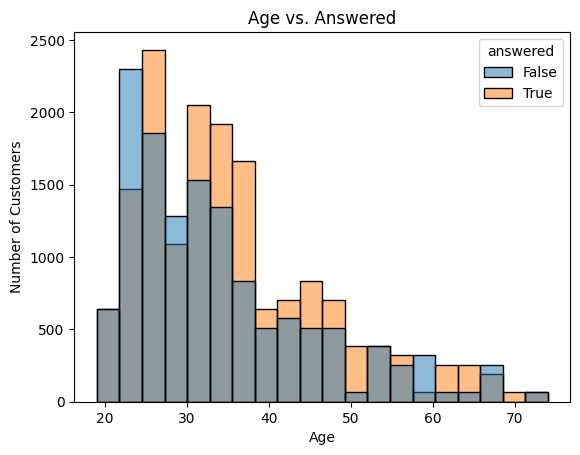

In [ ]:
sns.histplot(data=df_clean, x='age', hue='answered', bins=20)
plt.title('Age vs. Answered')
plt.xlabel('Age')
plt.ylabel('Number of Customers')
plt.show()

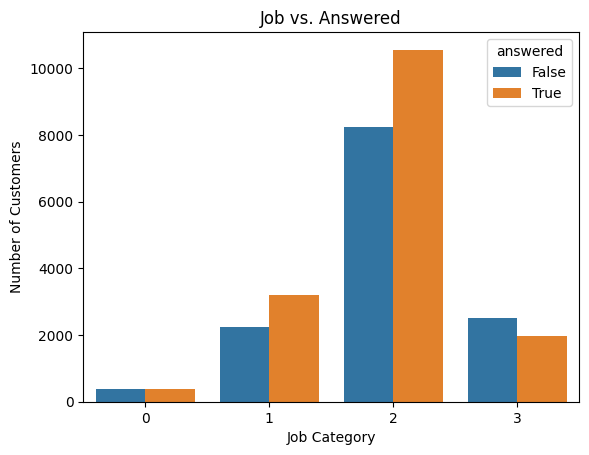

In [ ]:
sns.countplot(data=df_clean, x='job', hue='answered')
plt.title('Job vs. Answered')
plt.xlabel('Job Category')
plt.ylabel('Number of Customers')
plt.show()

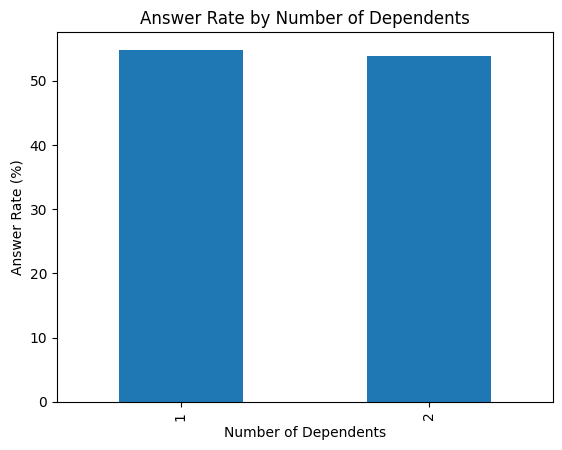

In [ ]:
df_clean.groupby('num_dependents')['answered'].mean().mul(100).plot(kind='bar')
plt.title('Answer Rate by Number of Dependents')
plt.xlabel('Number of Dependents')
plt.ylabel('Answer Rate (%)')
plt.show()

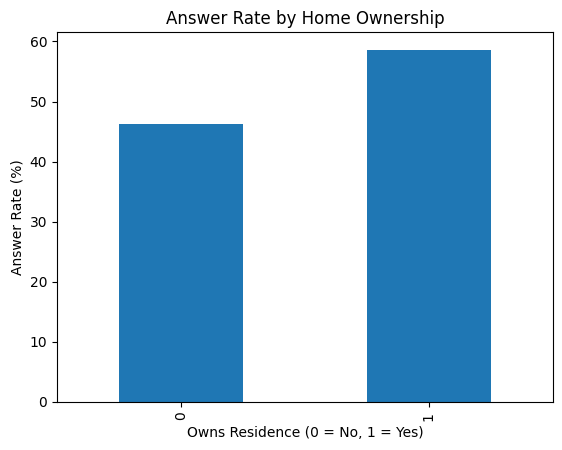

In [ ]:
df_clean.groupby('own_res')['answered'].mean().mul(100).plot(kind='bar')
plt.title('Answer Rate by Home Ownership')
plt.xlabel('Owns Residence (0 = No, 1 = Yes)')
plt.ylabel('Answer Rate (%)')
plt.show()

### Reflection:
3.6. Which variables show the strongest relationship with the target variable?

3.7. Did you find any variables that have a weak relationship with the target variable?  Should they be removed?

### ✍️ Your Response: 🔧
3.6. I noticed that customers with lower incomes were generally more likely to answer calls. Job category also seemed to make a difference, especially categories 1 and 2. Homeownership appeared to have a relationship with answering as well.

3.7.  The number of dependents didn't seem to have a strong relationship with whether someone answered. I would keep it in the model for now because it might still help when combined with other variables.

## Step 4: Modeling

Start with the baseline.  If we use no model at all, how good is our chance of predicting someone leaving?  Use a calculation to find the chances of someone leaving.

### Do the following:
4.1 Calculate the base probability of answering  

In [ ]:
df_clean['answered'].value_counts(normalize=True) * 100

,proportion
answered,
True,54.668746
False,45.331254


## 4.2: Split the training and testing datasets

### Do the following:
- split df_clean using train_test_split function

Notes:
- all remaining variables except answered should be in the x variable
- answered is in the y variable


In [ ]:
X = df_clean.drop(columns=['answered'])
y = df_clean['answered']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape)
print(X_test.shape)

(23595, 12)
(5899, 12)


## 4.3: Create a Decision Tree

### Do the following:
- Create a tree
- Display (visualize) the tree

Notes:
- Use all available attributes (except those that were eliminated in step 3)
- It is recommended to use the type "entropy" and a max_depth of 4

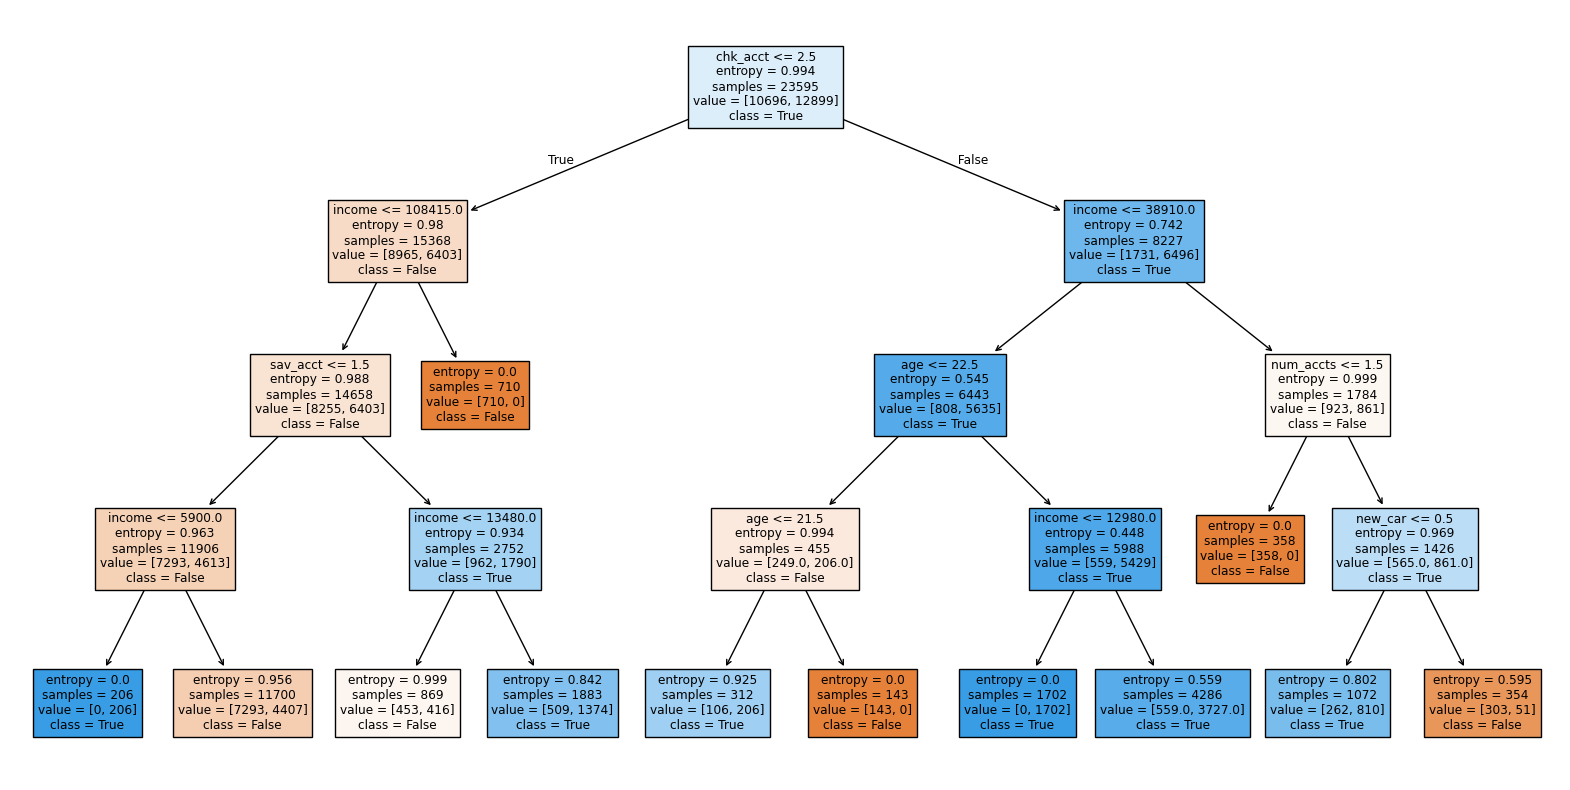

In [ ]:
model = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)
model.fit(X_train, y_train)
plt.figure(figsize=(20, 10))
plot_tree(model, feature_names=X.columns, class_names=['False', 'True'], filled=True)
plt.show()

## 4.4: Calculate the accuracy

This should be better than the base probability, or you have failed in your objective

### Do the following:
- Calculate the probability for your tree

In [ ]:
y_pred = model.predict(X_test)
print("Training Accuracy:", model.score(X_train, y_train))
print("Testing Accuracy:", accuracy_score(y_test, y_pred))
print("Base Probability:", y_train.value_counts(normalize=True).max())

Training Accuracy: 0.7325704598431871
Testing Accuracy: 0.7352093575182235
Base Probability: 0.5466836194108922


### Reflection:
1. What is the difference between the probability from the model compared to the base probability?
2. Is this difference a significant amount for the business?  

### ✍️ Your Response: 🔧
1. The model had an accuracy of 73.52%, compared to the base probability of 54.67%.

2. Yes, I think this is a significant improvement because the business can better predict which customers are likely to answer. This could help them prioritize calls, save time, and use their resources more efficiently.


### 4.5: Confusion Matrix

### Do the following
- Create a confusion matrix

This will show false positives, true positives, etc.

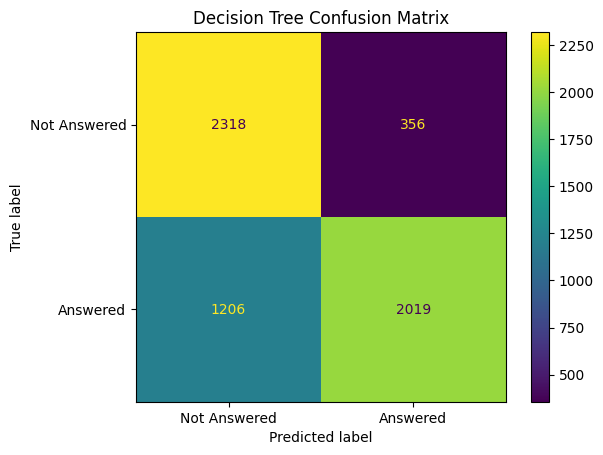

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=['Not Answered', 'Answered']).plot()
plt.title('Decision Tree Confusion Matrix')
plt.show()

Create a more visual, interpretable version of the matrix (hint - try using Seaborn Heatmap)

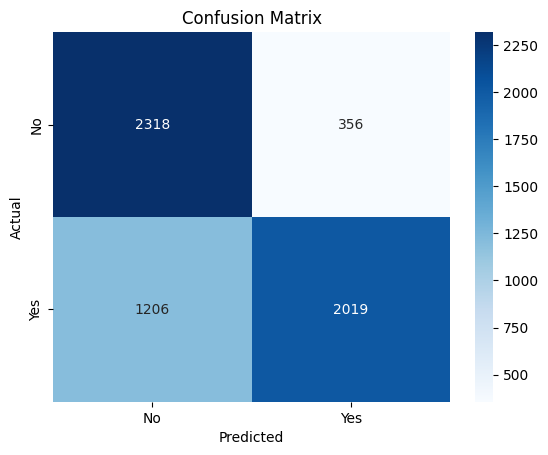

In [ ]:
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

# Step 5: Evaluate the Model

**Assumptions**

One of the simplifying assumptions we will make in this project is that all the customers who answer the phone will purchase a product. (This assumption is actually verified by the data.) To model "answered" in this case is therefore equivalent to modeling "purchased."

There are costs and benefits in this case. We will assume that customers purchase a product for 100 dollars. This was the average cost of AdviseInvest products, according to the Director of Sales.  Also, as we learned in the interview, the agent time to make the sale is worth 25 dollars. Profit would therefore be \$75 dollars for an answered call and a purchase. In sum:

**Benefit**: True positive. The customer is predicted to answer, does answer, and purchases a product for 100 dollars for a profit of 100 - 25 = 75.

**Cost**: False positive. The customer is predicted to answer, but does not answer, so there is a loss of 25. (We assume the agent cannot schedule another call at the last minute, or spends the entire time slot trying to make the call.)

When you create a calculation you can use:
- True answered * 75 -> These people purchased
- False answered * 25 -> You can't schedule another call

For this exercise, we propose that customers who are not predicted to answer will not be called, so there would be no benefits and no costs for them.  

### Do the following:
Calculate the Profit Using the Model

In [ ]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
model_profit = (tp * 75) - (fp * 25)
print("Model Profit: $", model_profit)

Model Profit: $ 142525


### 5.2 Compare to the Default Profit

### Do the following:
- Calculate the profit (revenue - costs) that would be expected if all customers are called

Notes:
- We can consider this a baseline case for profit since it does not require a model
- In other words, to calculate profit in this baseline scenario treat the customers who answer as true positives treat the customers who do not answer as false positives.

In [ ]:
default_profit = (y_test.sum() * 75) - ((~y_test).sum() * 25)
print("Default Profit: $", default_profit)
print("Model Profit: $", model_profit)
print("Difference: $", model_profit - default_profit)

Default Profit: $ 175025
Model Profit: $ 142525
Difference: $ -32500


### Reflection:
1. What is the difference in profit between calling all customers and calling customers that are recommended by the model?
2. Is this a significant amount for the business?  

### ✍️ Your Response: 🔧
1. Calling all customers resulted in a profit of 175,025, while using the model resulted in 142,525. This means the business would make 32,500 less by following the model's recommendations.

2. Yes, I think 32,500 is a significant difference. Even though the model was more accurate at predicting who would answer, it missed too many customers who actually would have answered. In this case, calling everyone would be more profitable.


## 5.3 Tune the Model

### Do the Following
- Create a new version of the tree with new parameters
- Calculate a new probability

Notes:
- Adjust the size or shape of the tree, then test the accuracy
- Keep changing these parameters until you end up with a tree with accuracy that is better than the initial model

In [ ]:
results = []

for depth in range(2, 16):
    test_model = DecisionTreeClassifier(criterion='entropy', max_depth=depth, random_state=42)
    test_model.fit(X_train, y_train)
    results.append([depth, test_model.score(X_test, y_test)])
display(pd.DataFrame(results, columns=['Depth', 'Accuracy']))
tuned_model = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=15,
    random_state=42
)
tuned_model.fit(X_train, y_train)
tuned_pred = tuned_model.predict(X_test)
print("Training Accuracy:", tuned_model.score(X_train, y_train))
print("Testing Accuracy:", accuracy_score(y_test, tuned_pred))

,Depth,Accuracy
0,2,0.654687
1,3,0.705882
2,4,0.735209
3,5,0.760637
4,6,0.781319
5,7,0.800983
6,8,0.818783
7,9,0.834209
8,10,0.844380
9,11,0.851161


Training Accuracy: 0.908582326764145
Testing Accuracy: 0.9099847431768097


In [ ]:
tn, fp, fn, tp = confusion_matrix(y_test, tuned_pred).ravel()
tuned_profit = (tp * 75) - (fp * 25)
print("Tuned Model Profit: $", tuned_profit)
print("Default Profit: $", default_profit)
print("Difference: $", tuned_profit - default_profit)

Tuned Model Profit: $ 206800
Default Profit: $ 175025
Difference: $ 31775


### 5.4 Apply the Model to New Customers

### Do the Following
- Import the "adviseinvest_new_customer_data.csv" file
- Copy and past the data cleanup steps from 2.1 and 2.2
- Using the tree model that you created in step 5.3, predict each customer for the target variable by feeding the new customer data into the model
- Predict the number of customers who will be yes/no for the target variable

In [ ]:
new_df = pd.read_csv('adviseinvest_new_customer_data.csv')
display(new_df.head())
print(new_df.shape)
print(new_df.isnull().sum())

,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,customer_id
0,30010,0,40,2,1,1,0,0,1,0,3,0,H1597
1,30510,0,54,2,1,0,1,0,0,0,2,0,P1446
2,12880,0,48,2,2,0,1,0,0,1,4,0,E1492
3,15530,0,44,2,1,0,1,0,0,0,2,0,W5143
4,46230,0,40,3,1,0,1,0,3,1,2,0,W4927


(1000, 13)
income            0
female            0
age               0
job               0
num_dependents    0
rent              0
own_res           0
new_car           0
chk_acct          0
sav_acct          0
num_accts         0
mobile            0
customer_id       0
dtype: int64


In [ ]:
customer_ids = new_df['customer_id']
new_X = new_df.drop(columns=['customer_id']).copy()
new_X = new_X[new_X['income'] >= 0]
new_X = new_X[new_X['age'] <= 100]
new_X = new_X[new_X['num_accts'] <= 100]
new_X = new_X.dropna()
new_X = new_X[new_X['female'].isin([0, 1, '0', '1'])].copy()
new_X['female'] = new_X['female'].astype(int)
new_X['new_car'] = new_X['new_car'].astype(int)
new_X = new_X[X_train.columns]
new_predictions = tuned_model.predict(new_X)
results = pd.DataFrame({'customer_id': new_df.loc[new_X.index, 'customer_id'],'predicted_answer': new_predictions})
display(results.head(10))
print("Predicted to Answer:", new_predictions.sum())
print("Predicted Not to Answer:", (~new_predictions).sum())

,customer_id,predicted_answer
0,H1597,False
1,P1446,False
2,E1492,True
3,W5143,True
4,W4927,False
5,M6161,True
6,U4472,False
7,H557,True
8,B54,True
9,L2217,True


Predicted to Answer: 492
Predicted Not to Answer: 508


# Step 6: Conclusion

### Reflection:
6.1: Did we improve our profit using the model?  

6.2: How could the model be utilized by the business?

### ✍️ Your Response: 🔧
6.1 Yes, after tuning, we improved our profit from 175,025 to 206,800 using the model. The original model was less profitable, but tuning it helped us make better predictions and improve profitability.

6.2 The business could use the model to predict which customers are most likely to answer their calls. This would help them prioritize customers, reduce unnecessary calls, and increase profits.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_10_classification.ipynb"

[NbConvertApp] Converting notebook assignment_10_classification.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 8 image(s).
[NbConvertApp] Writing 865915 bytes to assignment_10_classification.html
